<a href="https://colab.research.google.com/github/jimenezjos/Aplicaciones/blob/main/SIR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PROYECTO: Ajuste de parametros del modelo SIR

* 1. Grafica los dato
* 2. Programar la solución numerica del modelo SIR, con parametros libres
* 3. Plantear un ajuste por minimos cuadrados, $\chi^2(a,b)$
* 4. Usa el metodo MCMC (Metropois-Hastings) para optimizar $\chi$
* 5. Remplazar con pyMc en el enfoque bayesiano

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from matplotlib.patches import Ellipse
import matplotlib.transforms as transforms

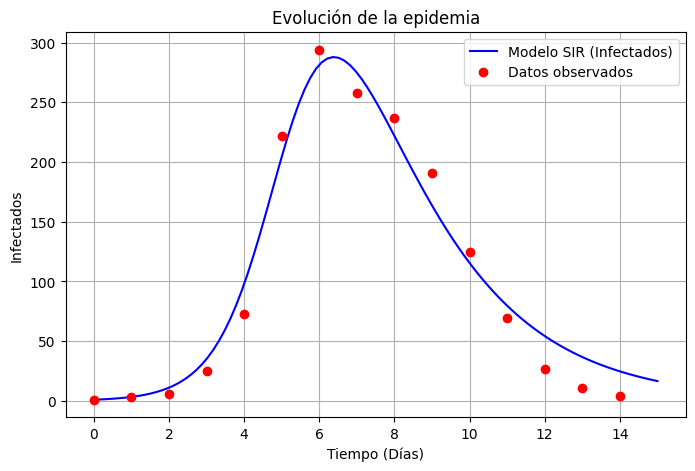

In [5]:
t_datos = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14])
I_datos = np.array([1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4])

plt.figure(figsize=(8, 5))

plt.plot(t, I, 'b-', label='Modelo SIR (Infectados)')
plt.plot(t_datos, I_datos, 'ro', label='Datos observados')

plt.xlabel('Tiempo (Días)')
plt.ylabel('Infectados')
plt.title('Evolución de la epidemia')
plt.legend()
plt.grid(True)
plt.show()

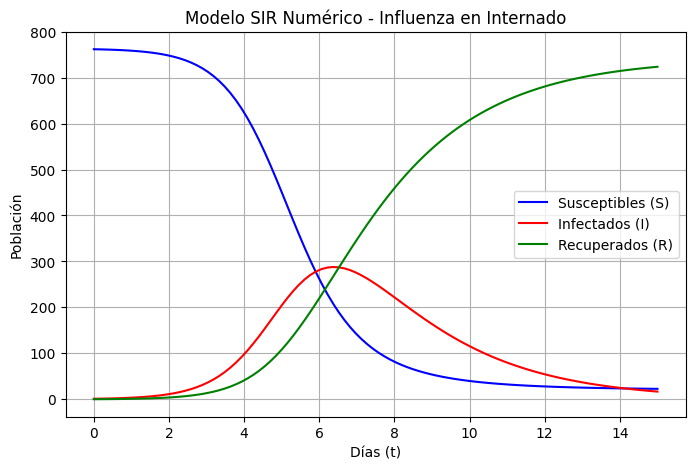

In [4]:
def sir_model(y, t, a, b):
    S, I, R = y
    dSdt = -a * S * I
    dIdt = a * S * I - b * I
    dRdt = b * I
    return [dSdt, dIdt, dRdt]

a = 0.00218
b = 0.4485

# Condiciones iniciales de la población
N = 763          # Población total (estudiantes)
I0 = 1           # Número inicial de infectados
S0 = N - I0      # Número inicial de susceptibles
R0 = 0           # Número inicial de recuperados
y0 = [S0, I0, R0]


t = np.linspace(0, 15, 100)

solucion = odeint(sir_model, y0, t, args=(a, b))
S, I, R = solucion.T

plt.figure(figsize=(8, 5))
plt.plot(t, S, 'b', label='Susceptibles (S)')
plt.plot(t, I, 'r', label='Infectados (I)')
plt.plot(t, R, 'g', label='Recuperados (R)')
plt.title('Modelo SIR Numérico - Influenza en Internado')
plt.xlabel('Días (t)')
plt.ylabel('Población')
plt.legend()
plt.grid(True)
plt.show()

In [6]:
def chi_cuadrada(a, b):
    sol = odeint(sir_model, y0, t_datos, args=(a, b))
    I_num = sol[:, 1]

    e_i = np.where(I_num <= 0, 1e-5, I_num)
    o_i = I_datos
    val_chi2 = np.sum(((o_i - e_i)**2) / e_i)

    return val_chi2
resultado = chi_cuadrada(a, b)
print(resultado)

71.73400335530064


Ejecutando MCMC...


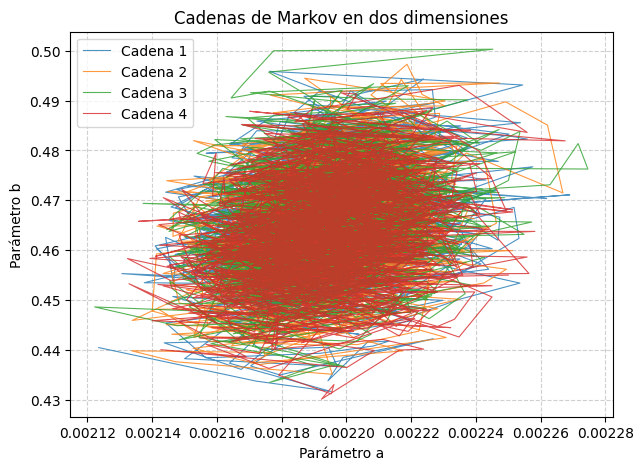

In [7]:
def mcmc_multicadena(n_cadenas, iteraciones, a_inis, b_inis, sigma_a=0.00005, sigma_b=0.005):
    cadenas_a = []
    cadenas_b = []

    min_chi2_global = np.inf
    mejor_a, mejor_b = 0, 0

    for c in range(n_cadenas):
        a_actual = a_inis[c]
        b_actual = b_inis[c]
        chi2_actual = chi_cuadrada(a_actual, b_actual)

        muestra_a, muestra_b = [], []

        for _ in range(iteraciones):
            a_prop = np.random.normal(a_actual, sigma_a)
            b_prop = np.random.normal(b_actual, sigma_b)

            if a_prop > 0 and b_prop > 0:
                chi2_prop = chi_cuadrada(a_prop, b_prop)

                if chi2_prop < min_chi2_global:
                    min_chi2_global = chi2_prop
                    mejor_a, mejor_b = a_prop, b_prop

                prob_aceptacion = np.exp(-0.5 * (chi2_prop - chi2_actual))
                if np.random.rand() < prob_aceptacion:
                    a_actual, b_actual = a_prop, b_prop
                    chi2_actual = chi2_prop

            muestra_a.append(a_actual)
            muestra_b.append(b_actual)

        cadenas_a.append(muestra_a)
        cadenas_b.append(muestra_b)

    return np.array(cadenas_a), np.array(cadenas_b), mejor_a, mejor_b, min_chi2_global

# Ejecución de 4 cadenas iniciando cerca de los valores conocidos
iteraciones = 3000
puntos_inicio_a = [0.00210, 0.00218, 0.00220, 0.00225]
puntos_inicio_b = [0.4400, 0.4485, 0.4500, 0.4550]

print("Ejecutando MCMC...")
cadenas_a, cadenas_b, mejor_a, mejor_b, min_chi2 = mcmc_multicadena(4, iteraciones, puntos_inicio_a, puntos_inicio_b)

# FIGURA 6: Cadenas de Markov
plt.figure(figsize=(7, 5))
colores = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
for i in range(4):
    plt.plot(cadenas_a[i], cadenas_b[i], color=colores[i], linewidth=0.8, alpha=0.8, label=f'Cadena {i+1}')
plt.xlabel('Parámetro a')
plt.ylabel('Parámetro b')
plt.title('Cadenas de Markov en dos dimensiones')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

<>:41: SyntaxWarning: invalid escape sequence '\c'
<>:41: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_1311/3334339693.py:41: SyntaxWarning: invalid escape sequence '\c'
  ax.plot(mejor_a, mejor_b, 'ro', markersize=6, label=f'Mínimo $\chi^2$ ({mejor_a:.5f}, {mejor_b:.5f})')



--- RESULTADOS DEL PUNTO 5 ---
Parámetros que minimizan Chi^2: a1 = a = 0.002194, a2 = b = 0.466665
Chi^2 mínimo alcanzado: 68.9115
Valores medios: a = 0.002194, b = 0.465418
Desviaciones medias: std(a) = 0.000020, std(b) = 0.010576
Matriz de covarianza:
[[4.02591204e-10 5.72624087e-08]
 [5.72624087e-08 1.11861181e-04]]


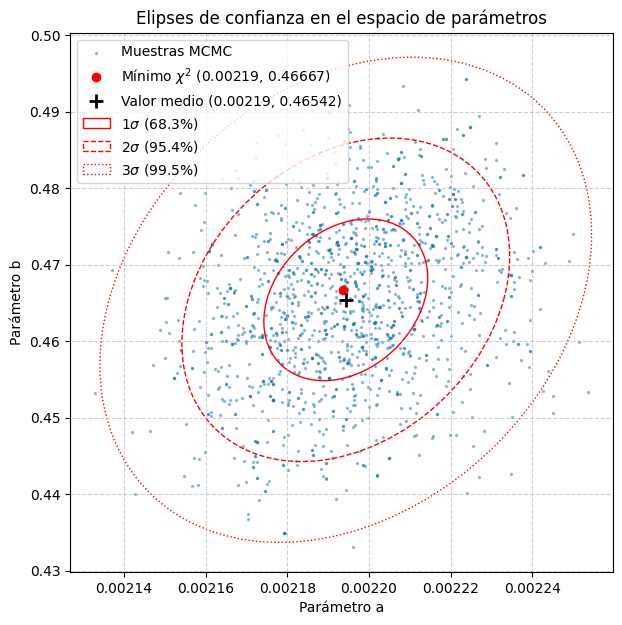

In [8]:
burn_in = int(0.2 * iteraciones)
a_validas = cadenas_a[:, burn_in:].flatten()
b_validas = cadenas_b[:, burn_in:].flatten()

# Cálculo de valores medios, desviaciones estándar y matriz de covarianza
a_medio = np.mean(a_validas)
b_medio = np.mean(b_validas)
std_a = np.std(a_validas)
std_b = np.std(b_validas)
matriz_cov = np.cov(a_validas, b_validas)

print("\n--- RESULTADOS DEL PUNTO 5 ---")
print(f"Parámetros que minimizan Chi^2: a1 = a = {mejor_a:.6f}, a2 = b = {mejor_b:.6f}")
print(f"Chi^2 mínimo alcanzado: {min_chi2:.4f}")
print(f"Valores medios: a = {a_medio:.6f}, b = {b_medio:.6f}")
print(f"Desviaciones medias: std(a) = {std_a:.6f}, std(b) = {std_b:.6f}")
print("Matriz de covarianza:")
print(matriz_cov)

# Función para trazar las elipses de confianza exactas mediante autovalores/autovectores
def plot_confidence_ellipse(x, y, ax, n_std, **kwargs):
    cov = np.cov(x, y)
    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]

    angle = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
    width, height = 2 * n_std * np.sqrt(vals)

    elipse = Ellipse(xy=(np.mean(x), np.mean(y)), width=width, height=height, angle=angle, fill=False, **kwargs)
    ax.add_patch(elipse)

# FIGURA 7: Elipses de confianza
fig, ax = plt.subplots(figsize=(7, 7))

# Muestra de puntos de las cadenas
muestreo_reducido = np.random.choice(len(a_validas), size=1500, replace=False)
ax.scatter(a_validas[muestreo_reducido], b_validas[muestreo_reducido], s=2, alpha=0.4, color='tab:blue', label='Muestras MCMC')

# Puntos de Mínimo Chi^2 y Valor Medio
ax.plot(mejor_a, mejor_b, 'ro', markersize=6, label=f'Mínimo $\chi^2$ ({mejor_a:.5f}, {mejor_b:.5f})')
ax.plot(a_medio, b_medio, 'k+', markersize=10, markeredgewidth=2, label=f'Valor medio ({a_medio:.5f}, {b_medio:.5f})')

# Elipses a 1, 2 y 3 sigmas (68.3%, 95.4% y 99.5%)
plot_confidence_ellipse(a_validas, b_validas, ax, n_std=1, edgecolor='red', linestyle='-', label=r'$1\sigma$ (68.3%)')
plot_confidence_ellipse(a_validas, b_validas, ax, n_std=2, edgecolor='red', linestyle='--', label=r'$2\sigma$ (95.4%)')
plot_confidence_ellipse(a_validas, b_validas, ax, n_std=3, edgecolor='red', linestyle=':', label=r'$3\sigma$ (99.5%)')

ax.set_xlabel('Parámetro a')
ax.set_ylabel('Parámetro b')
ax.set_title('Elipses de confianza en el espacio de parámetros')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.6)
plt.show()